In [ ]:
import pandas as pd
# 1. Cargar la base de datos indicando el separador punto y coma
df = pd.read_csv('Thyroid_Diff.csv', sep=',')

# 2. Ver tamaño (filas, columnas) y primeras 5 filas
print("dimensiones:", df.shape)
display(df.head())

# 3. Ver tipos de datos de cada columna
print("\nTipos de datos:")
print(df.dtypes)

# 4. Contar valores nulos por columna y filas duplicadas
print("\nValores nulos por columna:")
print(df.isnull().sum())
print("\nTotal de filas duplicadas:", df.duplicated().sum())



dimensiones: (383, 17)


,Age,Gender,Smoking,Hx Smoking,Hx Radiothreapy,Thyroid Function,Physical Examination,Adenopathy,Pathology,Focality,Risk,T,N,M,Stage,Response,Recurred
0,27,F,No,No,No,Euthyroid,Single nodular goiter-left,No,Micropapillary,Uni-Focal,Low,T1a,N0,M0,I,Indeterminate,No
1,34,F,No,Yes,No,Euthyroid,Multinodular goiter,No,Micropapillary,Uni-Focal,Low,T1a,N0,M0,I,Excellent,No
2,30,F,No,No,No,Euthyroid,Single nodular goiter-right,No,Micropapillary,Uni-Focal,Low,T1a,N0,M0,I,Excellent,No
3,62,F,No,No,No,Euthyroid,Single nodular goiter-right,No,Micropapillary,Uni-Focal,Low,T1a,N0,M0,I,Excellent,No
4,62,F,No,No,No,Euthyroid,Multinodular goiter,No,Micropapillary,Multi-Focal,Low,T1a,N0,M0,I,Excellent,No



Tipos de datos:
Age                      int64
Gender                  object
Smoking                 object
Hx Smoking              object
Hx Radiothreapy         object
Thyroid Function        object
Physical Examination    object
Adenopathy              object
Pathology               object
Focality                object
Risk                    object
T                       object
N                       object
M                       object
Stage                   object
Response                object
Recurred                object
dtype: object

Valores nulos por columna:
Age                     0
Gender                  0
Smoking                 0
Hx Smoking              0
Hx Radiothreapy         0
Thyroid Function        0
Physical Examination    0
Adenopathy              0
Pathology               0
Focality                0
Risk                    0
T                       0
N                       0
M                       0
Stage                   0
Response                

In [ ]:
# 1. Ver algunas de las filas duplicadas antes de decidir
print("Ejemplos de filas duplicadas:")
display(df[df.duplicated(keep=False)].sort_values(by='Age').head(6))

# 2. Eliminar duplicados y guardar en un nuevo dataframe limpio
df_limpio = df.drop_duplicates().copy()

# 3. Estandarizar textos quitar espacios invisibles al inicio o final por seguridad
for col in df_limpio.select_dtypes(include='object').columns:
    df_limpio[col] = df_limpio[col].str.strip()

print("Tamaño original:", df.shape)
print("Tamaño después de limpiar:", df_limpio.shape)

Ejemplos de filas duplicadas:


,Age,Gender,Smoking,Hx Smoking,Hx Radiothreapy,Thyroid Function,Physical Examination,Adenopathy,Pathology,Focality,Risk,T,N,M,Stage,Response,Recurred
168,21,F,No,No,No,Euthyroid,Single nodular goiter-right,No,Papillary,Uni-Focal,Low,T2,N0,M0,I,Excellent,No
136,21,F,No,No,No,Euthyroid,Single nodular goiter-right,No,Papillary,Uni-Focal,Low,T2,N0,M0,I,Excellent,No
161,22,F,No,No,No,Euthyroid,Single nodular goiter-right,No,Papillary,Uni-Focal,Low,T2,N0,M0,I,Excellent,No
196,22,F,No,No,No,Euthyroid,Single nodular goiter-right,No,Papillary,Uni-Focal,Low,T2,N0,M0,I,Excellent,No
121,26,F,No,No,No,Euthyroid,Multinodular goiter,No,Papillary,Uni-Focal,Low,T2,N0,M0,I,Excellent,No
138,26,F,No,No,No,Euthyroid,Multinodular goiter,No,Papillary,Uni-Focal,Low,T2,N0,M0,I,Excellent,No


Tamaño original: (383, 17)
Tamaño después de limpiar: (364, 17)


In [ ]:
# 1. Estadísticas de la variable numérica (Edad)
print("--- ESTADÍSTICAS DE LA EDAD ---")
print(df_limpio['Age'].describe())
print("Mediana de edad:", df_limpio['Age'].median())
print("Moda de edad:", df_limpio['Age'].mode()[0])

# 2. Conteo y porcentaje de nuestra variable objetivo (¿Reapareció o no?)
print("\n--- CONTEO DE REAPARICIÓN (Recurred) ---")
print(df_limpio['Recurred'].value_counts())
print("\nPorcentaje:")
print(df_limpio['Recurred'].value_counts(normalize=True) * 100)

--- ESTADÍSTICAS DE LA EDAD ---
count    364.00000
mean      41.25000
std       15.31436
min       15.00000
25%       30.00000
50%       38.00000
75%       52.00000
max       82.00000
Name: Age, dtype: float64
Mediana de edad: 38.0
Moda de edad: 31

--- CONTEO DE REAPARICIÓN (Recurred) ---
Recurred
No     256
Yes    108
Name: count, dtype: int64

Porcentaje:
Recurred
No     70.32967
Yes    29.67033
Name: proportion, dtype: float64


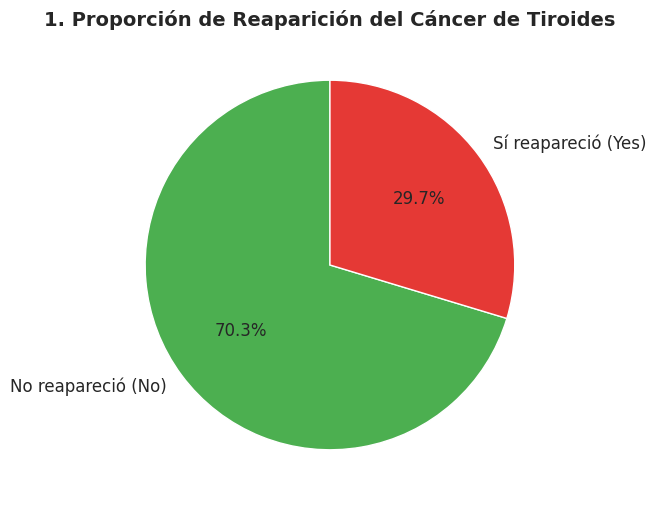

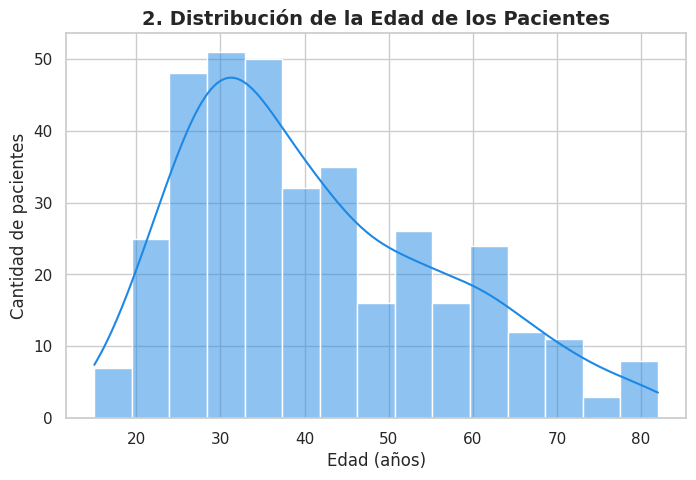

/tmp/ipykernel_610/1510652810.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_limpio, x='Recurred', y='Age', palette=['#4CAF50', '#E53935'])


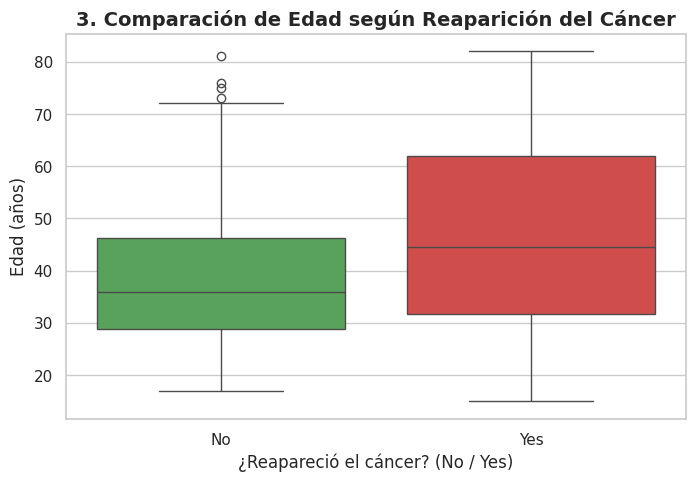

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# GRÁFICA 1: Gráfica de Pastel (Proporción general de reaparición)
plt.figure(figsize=(6, 6))
conteo = df_limpio['Recurred'].value_counts()
plt.pie(conteo, labels=['No reapareció (No)', 'Sí reapareció (Yes)'], autopct='%1.1f%%',
        startangle=90, colors=['#4CAF50', '#E53935'], textprops={'fontsize': 12})
plt.title('1. Proporción de Reaparición del Cáncer de Tiroides', fontsize=14, fontweight='bold')
plt.show()

# --- GRÁFICA 2: Histograma (Distribución de la edad de los pacientes) ---
plt.figure(figsize=(8, 5))
sns.histplot(data=df_limpio, x='Age', bins=15, kde=True, color='#1E88E5')
plt.title('2. Distribución de la Edad de los Pacientes', fontsize=14, fontweight='bold')
plt.xlabel('Edad (años)', fontsize=12)
plt.ylabel('Cantidad de pacientes', fontsize=12)
plt.show()

# --- GRÁFICA 3: Boxplot / Caja y bigote (Edad vs. Reaparición) ---
plt.figure(figsize=(8, 5))
sns.boxplot(data=df_limpio, x='Recurred', y='Age', palette=['#4CAF50', '#E53935'])
plt.title('3. Comparación de Edad según Reaparición del Cáncer', fontsize=14, fontweight='bold')
plt.xlabel('¿Reapareció el cáncer? (No / Yes)', fontsize=12)
plt.ylabel('Edad (años)', fontsize=12)
plt.show()


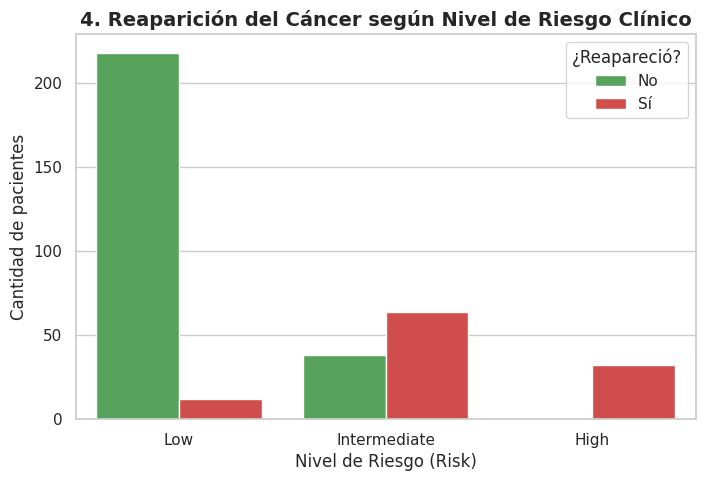

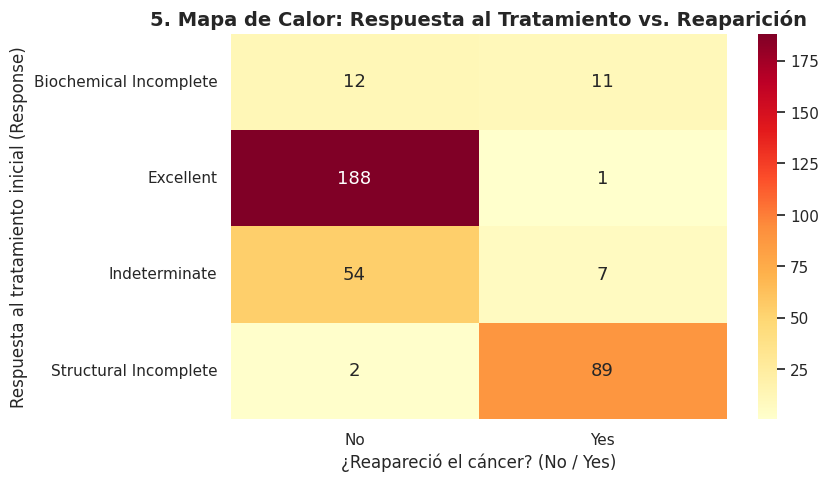

In [ ]:
# GRÁFICA 4: Gráfica de Barras Agrupadas (Nivel de Riesgo vs. Reaparición)
plt.figure(figsize=(8, 5))
sns.countplot(data=df_limpio, x='Risk', hue='Recurred',
              order=['Low', 'Intermediate', 'High'], palette=['#4CAF50', '#E53935'])
plt.title('4. Reaparición del Cáncer según Nivel de Riesgo Clínico', fontsize=14, fontweight='bold')
plt.xlabel('Nivel de Riesgo (Risk)', fontsize=12)
plt.ylabel('Cantidad de pacientes', fontsize=12)
plt.legend(title='¿Reapareció?', labels=['No', 'Sí'])
plt.show()

# GRÁFICA 5: Mapa de Calor / Heatmap (Respuesta al tratamiento vs. Reaparición)
plt.figure(figsize=(8, 5))
tabla_cruzada = pd.crosstab(df_limpio['Response'], df_limpio['Recurred'])
sns.heatmap(tabla_cruzada, annot=True, fmt='d', cmap='YlOrRd', cbar=True, annot_kws={'size': 13})
plt.title('5. Mapa de Calor: Respuesta al Tratamiento vs. Reaparición', fontsize=14, fontweight='bold')
plt.xlabel('¿Reapareció el cáncer? (No / Yes)', fontsize=12)
plt.ylabel('Respuesta al tratamiento inicial (Response)', fontsize=12)
plt.show()